# Judy's scratch: Rating prediction

**Question:** given a user and a recipe, can we predict how the user will rate that recipe?
- **Input:** user ID, recipe ID (plus recipe characteristics for the hybrid model)
- **Output:** rating from 1 to 5
- **Metrics:** RMSE (penalises big misses, e.g. predicting 5 for a 1-star review) and MAE (average size of a miss, in stars)

**Data:** our filtered splits from `judy.ipynb` (`filtered_train/validation/test.csv`, 80/10/10, rating 0 removed, users with 4+ reviews) and `filtered_recipes.csv` for recipe characteristics.

**Roadmap**
1. Baselines: global average, user average, recipe average, and a regularised user + recipe bias model
2. Collaborative filtering: item-based k-nearest neighbours (similar recipes)
3. Matrix factorization: SVD-style latent factors, plus Neural Collaborative Filtering (NCF)
4. Hybrid: Factorization Machine with recipe characteristics (cooking time, steps, ingredients, tags, calories), and a bias model whose recipe bias falls back on a prior predicted from recipe features (author, text, tags, ...)
5. Evaluation and analysis: compare RMSE/MAE on the test set and look at which users and recipes are hard to predict
6. A different setting: predicting the rating from the review text itself (TF-IDF + ridge regression), reported separately

**Validity:** every model is fit on train and tuned on validation only. The test set is scored **once**, in Section 5. Users or recipes never seen in train (cold start) fall back to the global average plus whatever the model can still use (e.g. recipe features).

Needs `numpy`, `pandas`, `matplotlib` and `torch` (`%pip install torch` if missing). Full run: about 5-10 minutes on a laptop CPU.

## Setup

In [1]:
import ast, copy, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

DATA_PATH = "../dataset/"
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count() or 1)
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})

train = pd.read_csv(DATA_PATH + "filtered_train.csv")
valid = pd.read_csv(DATA_PATH + "filtered_validation.csv")
test  = pd.read_csv(DATA_PATH + "filtered_test.csv")
recipes = pd.read_csv(DATA_PATH + "filtered_recipes.csv")

# integer ids for users / recipes seen in train; -1 = unseen (cold start)
user_index = pd.Index(train.user_id.unique())
recipe_index = pd.Index(train.recipe_id.unique())
NU, NI = len(user_index), len(recipe_index)
recipe_pos = pd.Index(recipes.id)            # row of each recipe in `recipes` (for features)

def make_split(df):
    u = user_index.get_indexer(df.user_id); i = recipe_index.get_indexer(df.recipe_id)
    p = recipe_pos.get_indexer(df.recipe_id)
    assert (p >= 0).all(), "every recipe should be in filtered_recipes.csv"
    return {"df": df, "u": u, "i": i, "r": df.rating.to_numpy(float),
            # torch versions: unseen ids point at an extra all-zero "padding" row
            "U": torch.tensor(np.where(u >= 0, u, NU)), "I": torch.tensor(np.where(i >= 0, i, NI)),
            "P": torch.tensor(p), "R": torch.tensor(df.rating.to_numpy(np.float32))}

SPLIT = {"train": make_split(train), "valid": make_split(valid), "test": make_split(test)}
u_tr, i_tr, r_tr = SPLIT["train"]["u"], SPLIT["train"]["i"], SPLIT["train"]["r"]
MU = r_tr.mean()

def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def mae(y, p):  return float(np.mean(np.abs(y - p)))
def lookup(values, idx, default=0.0):
    """values[idx], with `default` where idx == -1 (unseen user/recipe)."""
    out = np.full(len(idx), default, dtype=float); ok = idx >= 0; out[ok] = values[idx[ok]]; return out

models = {}        # model name -> function(split) returning predictions; filled in as we go
def val_score(name):
    p = np.clip(models[name](SPLIT["valid"]), 1, 5)
    return {"model": name, "val RMSE": rmse(SPLIT["valid"]["r"], p), "val MAE": mae(SPLIT["valid"]["r"], p)}

print(f"train {len(train):,} | validation {len(valid):,} | test {len(test):,} | recipes {len(recipes):,}")
print(f"users {NU:,} | recipes in train {NI:,} | global mean rating {MU:.3f}")
for s in ("valid", "test"):
    print(f"{s}: cold-start users {(SPLIT[s]['u'] < 0).mean():.2%} | cold-start recipes {(SPLIT[s]['i'] < 0).mean():.2%}")

train 631,414 | validation 78,927 | test 78,927 | recipes 190,323
users 25,527 | recipes in train 171,941 | global mean rating 4.683
valid: cold-start users 0.01% | cold-start recipes 12.87%
test: cold-start users 0.02% | cold-start recipes 12.70%


## 1. Baseline models
- **Global average:** predict the mean training rating for everyone.
- **User average / recipe average:** the user's (or recipe's) mean training rating; unseen users/recipes get the global average.
- **Bias model:** $\hat r_{u,i} = \mu + b_u + b_i$, where $b_u$ is how much user $u$ rates above/below average and $b_i$ the same for recipe $i$. Unlike plain averages, the biases are **regularised** ($\lambda_u, \lambda_i$), which pulls users/recipes with only a few ratings towards the global mean. Fit by alternating closed-form updates; $\lambda$s tuned on validation.

In [2]:
n_u = np.bincount(u_tr, minlength=NU); n_i = np.bincount(i_tr, minlength=NI)
user_mean = np.bincount(u_tr, r_tr, NU) / n_u
recipe_mean = np.bincount(i_tr, r_tr, NI) / n_i

models["Global average"] = lambda s: np.full(len(s["u"]), MU)
models["User average"]   = lambda s: lookup(user_mean, s["u"], MU)
models["Recipe average"] = lambda s: lookup(recipe_mean, s["i"], MU)

def fit_bias(lam_u, lam_i, iters=15):
    bu, bi = np.zeros(NU), np.zeros(NI)
    for _ in range(iters):
        bi = np.bincount(i_tr, r_tr - MU - bu[u_tr], NI) / (lam_i + n_i)
        bu = np.bincount(u_tr, r_tr - MU - bi[i_tr], NU) / (lam_u + n_u)
    return bu, bi

def predict_bias(b, s):
    return MU + lookup(b[0], s["u"]) + lookup(b[1], s["i"])

grid = [1, 2, 5, 10, 20]
bias_tbl = pd.DataFrame(index=pd.Index(grid, name="lambda_u"), columns=pd.Index(grid, name="lambda_i"), dtype=float)
for lu in grid:
    for li in grid:
        bias_tbl.loc[lu, li] = rmse(SPLIT["valid"]["r"], np.clip(predict_bias(fit_bias(lu, li), SPLIT["valid"]), 1, 5))
best_lu, best_li = bias_tbl.stack().idxmin()
BIAS = fit_bias(best_lu, best_li)
models["Bias model"] = lambda s: predict_bias(BIAS, s)
print(f"Best bias model: lambda_u={best_lu}, lambda_i={best_li}")
display(bias_tbl.round(4).style.set_caption("validation RMSE"))
pd.DataFrame([val_score(m) for m in models]).set_index("model").round(4)

Best bias model: lambda_u=5, lambda_i=10


lambda_i,1,2,5,10,20
lambda_u,,,,,
1,0.614800,0.608900,0.605600,0.605900,0.607400
2,0.613800,0.607600,0.603900,0.604000,0.605400
5,0.614000,0.607300,0.603000,0.602700,0.603900
10,0.615900,0.608800,0.604000,0.603500,0.604500
20,0.619300,0.611800,0.606700,0.605900,0.606800


,val RMSE,val MAE
model,,
Global average,0.6530,0.4819
User average,0.6215,0.4066
Recipe average,0.6945,0.4388
Bias model,0.6027,0.3992


## 2. Collaborative filtering: item-based k-nearest neighbours
Idea: to predict user $u$ on recipe $i$, look at the recipes $u$ already rated that are **similar** to $i$, and adjust the bias-model prediction by how much $u$ liked those recipes more or less than expected:

$$\hat r_{u,i} = \mu + b_u + b_i + \frac{\sum_{j \in N_k(i;u)} s_{ij}\,(r_{u,j} - \mu - b_u - b_j)}{\sum_{j} s_{ij} + \lambda}$$

- $s_{ij}$ = cosine similarity between recipes $i$ and $j$, computed on the bias-model **residuals** of the users who rated both, shrunk by $n_{ij}/(n_{ij}+5)$ so similarities based on one or two shared users count less. Only positive similarities are used.
- $N_k(i;u)$ = the $k$ most similar recipes that $u$ has rated. $k$ and $\lambda$ are tuned on validation.
- Recipes with no co-raters (common here, since most recipes have few reviews) get no neighbours, so the prediction falls back to the bias model.

In [3]:
bu, bi = BIAS
res_tr = r_tr - (MU + bu[u_tr] + bi[i_tr])                 # bias-model residuals on train
o = np.argsort(i_tr, kind="stable"); i_ptr = np.r_[0, np.cumsum(n_i)]
item_users, item_res = u_tr[o], res_tr[o]                  # raters of each recipe (CSR by recipe)
o = np.argsort(u_tr, kind="stable"); u_ptr = np.r_[0, np.cumsum(n_u)]
user_items, user_res = i_tr[o], res_tr[o]                  # recipes of each user (CSR by user)
item_norm = np.sqrt(np.bincount(i_tr, res_tr ** 2, NI)) + 1e-9

def raters_of(items):
    """(row in `items`, user, residual) for every train rating of the given recipes."""
    lens = i_ptr[items + 1] - i_ptr[items]
    idx = np.repeat(i_ptr[items] - np.cumsum(np.r_[0, lens[:-1]]), lens) + np.arange(lens.sum())
    return np.repeat(np.arange(len(items)), lens), item_users[idx], item_res[idx]

def knn_neighbours(s, K=50, shrink=5.0):
    """Top-K similar recipes (similarity, user's residual) for every query row, sorted by similarity."""
    sims, resid = np.zeros((len(s["u"]), K)), np.zeros((len(s["u"]), K))
    q = np.nonzero((s["u"] >= 0) & (s["i"] >= 0))[0]
    q = q[np.argsort(s["u"][q], kind="stable")]
    users = s["u"][q]; cuts = np.r_[0, np.nonzero(np.diff(users))[0] + 1, len(q)]
    for a, b in zip(cuts[:-1], cuts[1:]):                  # one user at a time
        rows, user = q[a:b], users[a]
        qi = s["i"][rows]
        its = user_items[u_ptr[user]:u_ptr[user + 1]]; ures = user_res[u_ptr[user]:u_ptr[user + 1]]
        br, bc, bv = raters_of(qi)
        shared = np.unique(bc)                             # only users who rated a query recipe matter
        ar, ac, av = raters_of(its)
        keep = np.isin(ac, shared); ar, ac, av = ar[keep], ac[keep], av[keep]
        if len(ar) == 0: continue
        B = np.zeros((len(qi), len(shared))); Bn = np.zeros_like(B)
        B[br, np.searchsorted(shared, bc)] = bv; Bn[br, np.searchsorted(shared, bc)] = 1
        A = np.zeros((len(its), len(shared))); An = np.zeros_like(A)
        A[ar, np.searchsorted(shared, ac)] = av; An[ar, np.searchsorted(shared, ac)] = 1
        co = Bn @ An.T                                     # number of shared raters
        sim = (B @ A.T) / (item_norm[qi][:, None] * item_norm[its][None, :]) * co / (co + shrink)
        sim[sim < 0] = 0
        k = min(K, sim.shape[1])
        top = np.argsort(-sim, axis=1)[:, :k]
        sims[rows, :k] = np.take_along_axis(sim, top, 1); resid[rows, :k] = ures[top]
    return sims, resid

def predict_knn(s, nb, k, lam):
    sims, resid = nb[0][:, :k], nb[1][:, :k]
    return predict_bias(BIAS, s) + (sims * resid).sum(1) / (sims.sum(1) + lam)

t0 = time.time()
NB = {"valid": knn_neighbours(SPLIT["valid"])}
print(f"neighbours for validation: {time.time() - t0:.1f}s | rows with at least one similar recipe: {(NB['valid'][0][:, 0] > 0).mean():.1%}")

knn_tbl = pd.DataFrame([{"k": k, "lambda": lam,
                         "val RMSE": rmse(SPLIT["valid"]["r"], np.clip(predict_knn(SPLIT["valid"], NB["valid"], k, lam), 1, 5))}
                        for k in (5, 10, 20, 50) for lam in (0.5, 1, 2, 5)])
best = knn_tbl.loc[knn_tbl["val RMSE"].idxmin()]
KNN_K, KNN_LAM = int(best["k"]), float(best["lambda"])
def knn_model(s):
    name = "valid" if s is SPLIT["valid"] else "test"
    if name not in NB: NB[name] = knn_neighbours(s)
    return predict_knn(s, NB[name], KNN_K, KNN_LAM)
models["Item kNN (CF)"] = knn_model
print(f"Best kNN: k={KNN_K}, lambda={KNN_LAM}")
display(knn_tbl.pivot(index="k", columns="lambda", values="val RMSE").round(4).style.set_caption("validation RMSE"))
pd.DataFrame([val_score(m) for m in models]).set_index("model").round(4)

neighbours for validation: 8.8s | rows with at least one similar recipe: 66.8%
Best kNN: k=50, lambda=1.0


lambda,0.500000,1.000000,2.000000,5.000000
k,,,,
5,0.602400,0.602400,0.602400,0.602600
10,0.602400,0.602300,0.602400,0.602500
20,0.602400,0.602300,0.602400,0.602500
50,0.602300,0.602300,0.602400,0.602500


,val RMSE,val MAE
model,,
Global average,0.6530,0.4819
User average,0.6215,0.4066
Recipe average,0.6945,0.4388
Bias model,0.6027,0.3992
Item kNN (CF),0.6023,0.3966


## 3. Matrix factorization (SVD) and Neural Collaborative Filtering
**SVD-style matrix factorization** ("Funk SVD", the model usually called SVD in recommender systems): each user and recipe gets a vector of $k$ latent factors, and

$$\hat r_{u,i} = \mu + b_u + b_i + p_u \cdot q_i$$

Classic linear-algebra SVD needs a complete matrix, but 99.99% of user-recipe pairs are missing, so instead we learn $p_u, q_i, b_u, b_i$ by minimising squared error on the known ratings plus an L2 penalty ($\lambda_b$ on biases, $\lambda_f$ on factors), with Adam in PyTorch.

**Neural Collaborative Filtering (NCF):** same biases, but $p_u \cdot q_i$ is replaced by a small neural network on $[p_u, q_i]$ (64 → 32 → 1 with ReLU and dropout), so the user-recipe interaction can be non-linear.

All PyTorch models share one training loop: mini-batches of 4,096, early stopping on validation RMSE (stop after 3 epochs without improvement, keep the best epoch). Grids are small to keep the run time reasonable.

Best SVD: {'k': 32, 'lam_b': 7.0, 'lam_f': 20}


,k,lam_b,lam_f,best epoch,val RMSE,seconds
0,8,7.0,5,4,0.6057,7
1,8,7.0,20,12,0.6030,15
2,32,7.0,5,4,0.6066,20
3,32,7.0,20,12,0.6030,42


Best NCF: {'k': 32, 'lam_b': 7.0, 'lam_f': 20}


,k,lam_b,lam_f,best epoch,val RMSE,seconds
0,32,7.0,5,1,0.6047,13
1,32,7.0,20,2,0.6040,16


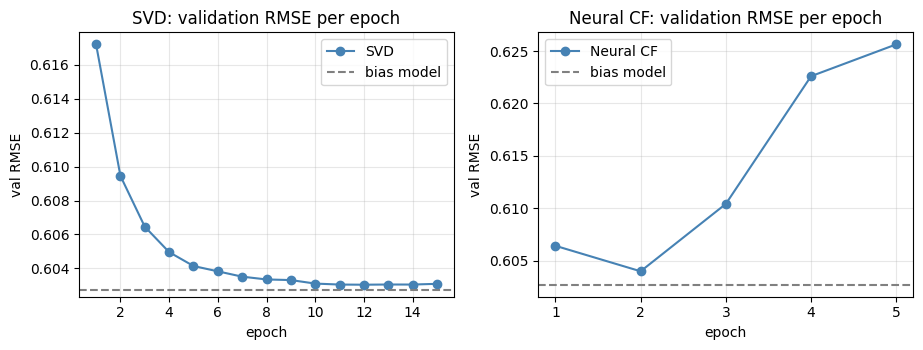

,val RMSE,val MAE
model,,
Global average,0.6530,0.4819
User average,0.6215,0.4066
Recipe average,0.6945,0.4388
Bias model,0.6027,0.3992
Item kNN (CF),0.6023,0.3966
SVD (matrix factorization),0.6030,0.3974
Neural CF,0.6040,0.4103


In [4]:
N_TRAIN = len(train)

def train_torch(model, lam_b, lam_f, epochs=15, lr=0.005, batch=4096, patience=3):
    """Train with MSE + L2 penalty; early-stop on validation RMSE. Returns model at best epoch and the history."""
    torch.manual_seed(SEED)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr, va = SPLIT["train"], SPLIT["valid"]
    best, best_state, best_ep, hist = np.inf, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(N_TRAIN)
        for a in range(0, N_TRAIN, batch):
            b = perm[a:a + batch]
            loss = ((model(tr["U"][b], tr["I"][b], tr["P"][b]) - tr["R"][b]) ** 2).mean() + model.penalty(lam_b, lam_f) / N_TRAIN
            opt.zero_grad(); loss.backward(); opt.step()
        e = rmse(va["r"], torch_predict(model, va)); hist.append(e)
        if e < best: best, best_ep, best_state = e, ep, copy.deepcopy(model.state_dict())
        elif ep - best_ep >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, hist, best_ep

def torch_predict(model, s):
    model.eval()
    with torch.no_grad():
        return model(s["U"], s["I"], s["P"]).clamp(1, 5).numpy().astype(float)

def emb(n, dim, std):
    """Embedding with an extra all-zero padding row (index n) for unseen users/recipes."""
    e = torch.nn.Embedding(n + 1, dim, padding_idx=n)
    torch.nn.init.normal_(e.weight, 0, std) if std > 0 else torch.nn.init.zeros_(e.weight)
    with torch.no_grad(): e.weight[n] = 0
    return e

class SVD(torch.nn.Module):
    def __init__(s, k):
        super().__init__()
        s.bu, s.bi = emb(NU, 1, 0), emb(NI, 1, 0)
        s.p, s.q = emb(NU, k, 0.01), emb(NI, k, 0.01)
    def forward(s, U, I, P):
        return MU + s.bu(U).squeeze(1) + s.bi(I).squeeze(1) + (s.p(U) * s.q(I)).sum(1)
    def penalty(s, lam_b, lam_f):
        return lam_b * (s.bu.weight.pow(2).sum() + s.bi.weight.pow(2).sum()) + lam_f * (s.p.weight.pow(2).sum() + s.q.weight.pow(2).sum())

class NCF(torch.nn.Module):
    def __init__(s, k, hidden=64, dropout=0.2):
        super().__init__()
        s.bu, s.bi = emb(NU, 1, 0), emb(NI, 1, 0)
        s.p, s.q = emb(NU, k, 0.01), emb(NI, k, 0.01)
        s.mlp = torch.nn.Sequential(torch.nn.Linear(2 * k, hidden), torch.nn.ReLU(), torch.nn.Dropout(dropout),
                                    torch.nn.Linear(hidden, hidden // 2), torch.nn.ReLU(), torch.nn.Linear(hidden // 2, 1))
    def forward(s, U, I, P):
        return MU + s.bu(U).squeeze(1) + s.bi(I).squeeze(1) + s.mlp(torch.cat([s.p(U), s.q(I)], 1)).squeeze(1)
    def penalty(s, lam_b, lam_f):
        return lam_b * (s.bu.weight.pow(2).sum() + s.bi.weight.pow(2).sum()) + lam_f * (s.p.weight.pow(2).sum() + s.q.weight.pow(2).sum())

def tune(make, configs, label):
    rows, best = [], None
    for cfg in configs:
        t0 = time.time()
        m, hist, ep = train_torch(make(cfg), cfg["lam_b"], cfg["lam_f"])
        rows.append({**cfg, "best epoch": ep, "val RMSE": min(hist), "seconds": round(time.time() - t0)})
        if best is None or min(hist) < best[0]: best = (min(hist), m, hist, cfg)
    print(f"Best {label}: {best[3]}")
    return best, pd.DataFrame(rows)

LAM_B = 7.0    # bias penalty, close to the tuned bias-model lambdas
svd_best, svd_tbl = tune(lambda c: SVD(c["k"]),
                         [{"k": k, "lam_b": LAM_B, "lam_f": lf} for k in (8, 32) for lf in (5, 20)], "SVD")
models["SVD (matrix factorization)"] = lambda s, m=svd_best[1]: torch_predict(m, s)
display(svd_tbl.round(4))

ncf_best, ncf_tbl = tune(lambda c: NCF(c["k"]),
                         [{"k": 32, "lam_b": LAM_B, "lam_f": lf} for lf in (5, 20)], "NCF")
models["Neural CF"] = lambda s, m=ncf_best[1]: torch_predict(m, s)
display(ncf_tbl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14 / 3 * 2, 3.6))
for a, (name, best) in zip(ax, [("SVD", svd_best), ("Neural CF", ncf_best)]):
    a.plot(range(1, len(best[2]) + 1), best[2], marker="o", color="steelblue", label=name)
    a.axhline(val_score("Bias model")["val RMSE"], c="gray", ls="--", label="bias model")
    a.set_title(f"{name}: validation RMSE per epoch"); a.set_xlabel("epoch"); a.set_ylabel("val RMSE"); a.legend()
plt.tight_layout(); plt.show()
pd.DataFrame([val_score(m) for m in models]).set_index("model").round(4)

## 4. Hybrid model: Factorization Machine with recipe characteristics
A **Factorization Machine (FM)** treats the user, the recipe and each recipe characteristic as features. Every feature gets a weight and a latent vector, and every *pair* of features interacts through the dot product of their vectors, so the model can learn things like "this user likes quick recipes" or "chocolate + dessert recipes rate well":

$$\hat r = \mu + \sum_f w_f x_f + \sum_{f < g} (v_f \cdot v_g)\, x_f x_g$$

Recipe features (from `filtered_recipes.csv`):
- cooking time (bucketed: ≤10 min, ≤20, ≤30, ≤45, ≤60, ≤90, ≤2 h, ≤4 h, ≤8 h, longer)
- number of steps and number of ingredients (one feature per value)
- calories (bucketed)
- ingredients and tags (one feature each, for those used by ≥50 training recipes; weighted $1/\sqrt{n}$ so long lists don't dominate)

The key benefit: a recipe never seen in train has no learned recipe weight, but its **features** still carry information, which helps cold-start recipes.

In [5]:
t0 = time.time()
ingr_lists = recipes.ingredients.map(ast.literal_eval)
tag_lists = recipes.tags.map(ast.literal_eval)
calories = recipes.nutrition.map(lambda x: ast.literal_eval(x)[0])

in_train = recipes.id.isin(set(train.recipe_id)).to_numpy()
ingr_count = pd.Series([x for l in ingr_lists[in_train] for x in l]).value_counts()
tag_count = pd.Series([x for l in tag_lists[in_train] for x in l]).value_counts()
ING, TAG = set(ingr_count[ingr_count >= 50].index), set(tag_count[tag_count >= 50].index)

vocab = {}
def fid(name): return vocab.setdefault(name, len(vocab))
def bucket(v, edges): return int(np.searchsorted(edges, v, side="right"))
feat_rows = []
for m, st, ni_, ings, tags, cal in zip(recipes.minutes, recipes.n_steps, recipes.n_ingredients, ingr_lists, tag_lists, calories):
    f = [(fid(f"minutes_{bucket(m, [10, 20, 30, 45, 60, 90, 120, 240, 480])}"), 1.0),
         (fid(f"steps_{min(st, 25)}"), 1.0), (fid(f"n_ingredients_{ni_}"), 1.0),
         (fid(f"calories_{bucket(cal, [100, 200, 300, 400, 600, 800, 1200])}"), 1.0)]
    gi, gt = [x for x in ings if x in ING], [x for x in tags if x in TAG]
    f += [(fid("ingredient_" + x), 1 / np.sqrt(len(gi))) for x in gi]
    f += [(fid("tag_" + x), 1 / np.sqrt(len(gt))) for x in gt]
    feat_rows.append(f)
NF, L = len(vocab), max(map(len, feat_rows))
FEAT_IDX = np.full((len(recipes), L), NF); FEAT_W = np.zeros((len(recipes), L), np.float32)
for r_, f in enumerate(feat_rows):
    FEAT_IDX[r_, :len(f)] = [a for a, _ in f]; FEAT_W[r_, :len(f)] = [w for _, w in f]
FEAT_IDX, FEAT_W = torch.tensor(FEAT_IDX), torch.tensor(FEAT_W)
print(f"{NF:,} recipe features ({len(ING):,} ingredients, {len(TAG):,} tags, plus time/steps/ingredient-count/calorie buckets) "
      f"| up to {L} per recipe | built in {time.time() - t0:.0f}s")

class FM(torch.nn.Module):
    def __init__(s, k):
        super().__init__()
        s.wu, s.wi, s.wf = emb(NU, 1, 0), emb(NI, 1, 0), emb(NF, 1, 0)
        s.vu, s.vi, s.vf = emb(NU, k, 0.01), emb(NI, k, 0.01), emb(NF, k, 0.01)
    def forward(s, U, I, P):
        fi, fw = FEAT_IDX[P], FEAT_W[P]
        linear = MU + s.wu(U).squeeze(1) + s.wi(I).squeeze(1) + (s.wf(fi).squeeze(2) * fw).sum(1)
        V = torch.cat([s.vu(U).unsqueeze(1), s.vi(I).unsqueeze(1), s.vf(fi) * fw.unsqueeze(2)], 1)
        pairwise = 0.5 * (V.sum(1).pow(2) - V.pow(2).sum(1)).sum(1)      # sum over all feature pairs
        return linear + pairwise
    def penalty(s, lam_b, lam_f):
        return lam_b * sum(e.weight.pow(2).sum() for e in (s.wu, s.wi, s.wf)) + lam_f * sum(e.weight.pow(2).sum() for e in (s.vu, s.vi, s.vf))

fm_best, fm_tbl = tune(lambda c: FM(c["k"]), [{"k": 16, "lam_b": LAM_B, "lam_f": lf} for lf in (5, 20)], "FM")
models["Hybrid FM (+ recipe features)"] = lambda s, m=fm_best[1]: torch_predict(m, s)
display(fm_tbl.round(4))
pd.DataFrame([val_score(m) for m in models]).set_index("model").round(4)

2,749 recipe features (2,265 ingredients, 427 tags, plus time/steps/ingredient-count/calorie buckets) | up to 80 per recipe | built in 15s


Best FM: {'k': 16, 'lam_b': 7.0, 'lam_f': 20}


,k,lam_b,lam_f,best epoch,val RMSE,seconds
0,16,7.0,5,2,0.6033,33
1,16,7.0,20,4,0.6018,38


,val RMSE,val MAE
model,,
Global average,0.6530,0.4819
User average,0.6215,0.4066
Recipe average,0.6945,0.4388
Bias model,0.6027,0.3992
Item kNN (CF),0.6023,0.3966
SVD (matrix factorization),0.6030,0.3974
Neural CF,0.6040,0.4103
Hybrid FM (+ recipe features),0.6018,0.3963


## 4b. Bias model with a feature-predicted recipe prior
The bias model gives a recipe it has never seen $b_i = 0$ ("perfectly average"). But we still know the recipe's **author**, its cooking time, tags, ingredients and the words in its name and description. So instead of 0, we *predict* the recipe's bias from those features and use that as the default (the "prior"):

$$\hat r_{u,i} = \mu + b_u + \underbrace{x_i \cdot \beta}_{\hat b_i\text{: feature-predicted bias}} + \delta_i$$

- $x_i$ = recipe features: the same buckets as the FM (time, steps, ingredient count, calories) plus submission year, ingredients/tags used by ≥20 training recipes, **author** (`contributor_id`), and words from the name + description used by ≥50 training recipes (multi-valued groups weighted $1/\sqrt{n}$).
- $\beta$ = ridge regression weights (penalty $\alpha$), shared across recipes, so a new recipe by a known author, or with "chocolate" and "dessert" in it, gets their learned effects.
- $\delta_i$ = the recipe's own deviation from its prior, regularised by $\lambda_i$. Fitting it in closed form gives $b_i = \frac{\sum (r - \mu - b_u) + \lambda_i \hat b_i}{n_i + \lambda_i}$: a recipe with no ratings uses $\hat b_i$, a recipe with a few ratings blends the two, and a popular recipe is driven by its own ratings.

Fit by alternating closed-form updates for $\delta$ and $b_u$ (as in Section 1) with a ridge solve for $\beta$ (conjugate gradient on sparse features, numpy only). $\alpha$ and $\lambda_i$ tuned on validation.

In [6]:
t0 = time.time()
words = (recipes.name.fillna("") + " " + recipes.description.fillna("")).str.lower().str.findall(r"[a-z]+").map(lambda l: sorted(set(l)))
def common(lists, k):
    c = pd.Series([x for l in lists[in_train] for x in l]).value_counts(); return set(c[c >= k].index)
ING20, TAG20, WRD = common(ingr_lists, 20), common(tag_lists, 20), common(words, 50)
authors_in_train = set(recipes.contributor_id[in_train])

pvocab, X_rows, X_cols, X_vals = {}, [], [], []
def pfid(name): return pvocab.setdefault(name, len(pvocab))
for r_, (m, st, ni_, ings, tags, cal, au, sub, wd) in enumerate(zip(
        recipes.minutes, recipes.n_steps, recipes.n_ingredients, ingr_lists, tag_lists, calories,
        recipes.contributor_id, recipes.submitted, words)):
    f = [(f"minutes_{bucket(m, [10, 20, 30, 45, 60, 90, 120, 240, 480])}", 1.0), (f"steps_{min(st, 25)}", 1.0),
         (f"n_ingredients_{min(ni_, 20)}", 1.0), (f"calories_{bucket(cal, [100, 200, 300, 400, 600, 800, 1200])}", 1.0),
         (f"year_{sub[:4]}", 1.0)]
    if au in authors_in_train: f.append((f"author_{au}", 1.0))
    for prefix, items in (("ingredient_", [x for x in ings if x in ING20]), ("tag_", [x for x in tags if x in TAG20]),
                          ("word_", [x for x in wd if x in WRD])):
        f += [(prefix + x, 1 / np.sqrt(len(items))) for x in items]
    for name, v in f: X_rows.append(r_); X_cols.append(pfid(name)); X_vals.append(v)
X_rows, X_cols, X_vals = np.array(X_rows), np.array(X_cols), np.array(X_vals)
NPF, NR = len(pvocab), len(recipes)
print(f"{NPF:,} prior features ({len(authors_in_train):,} authors, {len(WRD):,} words, {len(ING20):,} ingredients, {len(TAG20):,} tags) "
      f"| built in {time.time() - t0:.0f}s")

def Xv(b):  return np.bincount(X_rows, X_vals * b[X_cols], NR)      # X @ beta   (one value per recipe)
def XTv(v): return np.bincount(X_cols, X_vals * v[X_rows], NPF)     # X.T @ v
p_tr = SPLIT["train"]["P"].numpy()
w_recipe = np.bincount(p_tr, minlength=NR).astype(float)           # ratings per recipe: ridge is fit at the rating level

def fit_prior(alpha, lam_i, lam_u=best_lu, iters=12, cg_iters=15):
    beta, bu, delta = np.zeros(NPF), np.zeros(NU), np.zeros(NI)
    A = lambda b: XTv(w_recipe * Xv(b)) + alpha * b
    for _ in range(iters):
        f = Xv(beta)[p_tr]
        delta = np.bincount(i_tr, r_tr - MU - bu[u_tr] - f, NI) / (lam_i + n_i)
        bu = np.bincount(u_tr, r_tr - MU - f - delta[i_tr], NU) / (lam_u + n_u)
        rhs = XTv(np.bincount(p_tr, r_tr - MU - bu[u_tr] - delta[i_tr], NR))
        res = rhs - A(beta); d = res.copy(); rs = res @ res            # conjugate gradient, warm-started
        for _ in range(cg_iters):
            Ad = A(d); a = rs / (d @ Ad); beta += a * d; res -= a * Ad
            rs_new = res @ res
            if rs_new < 1e-10: break
            d = res + rs_new / rs * d; rs = rs_new
    return {"bu": bu, "delta": delta, "beta": beta, "b_hat": Xv(beta)}

def predict_prior(m, s):
    return MU + lookup(m["bu"], s["u"]) + lookup(m["delta"], s["i"]) + m["b_hat"][s["P"].numpy()]

va, va_cold = SPLIT["valid"], SPLIT["valid"]["i"] < 0
p_bias = np.clip(models["Bias model"](va), 1, 5)
prior_rows, PRIOR, best_rmse = [], None, np.inf
for alpha in (20, 100):
    for lam_i in (best_li / 2, best_li):
        t1 = time.time(); m = fit_prior(alpha, lam_i); p = np.clip(predict_prior(m, va), 1, 5)
        prior_rows.append({"alpha": alpha, "lambda_i": lam_i, "val RMSE": rmse(va["r"], p),
                           "val RMSE (cold recipes)": rmse(va["r"][va_cold], p[va_cold]),
                           "val RMSE (warm recipes)": rmse(va["r"][~va_cold], p[~va_cold]), "seconds": round(time.time() - t1)})
        if prior_rows[-1]["val RMSE"] < best_rmse: best_rmse, PRIOR, PRIOR_CFG = prior_rows[-1]["val RMSE"], m, (alpha, lam_i)
models["Bias + feature prior"] = lambda s: predict_prior(PRIOR, s)
print(f"Best prior model: alpha={PRIOR_CFG[0]}, lambda_i={PRIOR_CFG[1]} | bias model on validation: "
      f"{rmse(va['r'], p_bias):.4f} overall, {rmse(va['r'][va_cold], p_bias[va_cold]):.4f} cold recipes")
display(pd.DataFrame(prior_rows).round(4))

# which features push the predicted bias most? (only features used by >= 20 training recipes, so the list isn't just rare authors)
used = np.bincount(X_cols[in_train[X_rows]], minlength=NPF)
names_f = np.array(sorted(pvocab, key=pvocab.get)); ok = used >= 20
order = np.argsort(PRIOR["beta"][ok])
print("most negative:", ", ".join(f"{n} ({b:+.2f})" for n, b in zip(names_f[ok][order[:8]], PRIOR["beta"][ok][order[:8]])))
print("most positive:", ", ".join(f"{n} ({b:+.2f})" for n, b in zip(names_f[ok][order[::-1][:8]], PRIOR["beta"][ok][order[::-1][:8]])))
pd.DataFrame([val_score(m) for m in models]).set_index("model").round(4)

30,659 prior features (21,293 authors, 5,077 words, 3,749 ingredients, 463 tags) | built in 18s


Best prior model: alpha=100, lambda_i=10 | bias model on validation: 0.6027 overall, 0.7146 cold recipes


,alpha,lambda_i,val RMSE,val RMSE (cold recipes),val RMSE (warm recipes),seconds
0,20,5.0,0.5999,0.7014,0.5834,23
1,20,10.0,0.5991,0.7020,0.5824,23
2,100,5.0,0.5998,0.7026,0.5831,23
3,100,10.0,0.5990,0.7031,0.5821,22


most negative: word_rsc (-0.36), tag_crock-pot-slow-cooker (-0.20), word_review (-0.19), tag_healthy (-0.16), word_crock (-0.16), word_casserole (-0.15), ingredient_cocoa powder (-0.14), ingredient_unsweetened cocoa (-0.14)
most positive: tag_beverages (+0.17), ingredient_taco seasoning (+0.15), tag_stews (+0.14), word_grilled (+0.14), ingredient_salmon fillets (+0.12), word_roast (+0.12), tag_roast-beef (+0.12), author_594139 (+0.11)


,val RMSE,val MAE
model,,
Global average,0.6530,0.4819
User average,0.6215,0.4066
Recipe average,0.6945,0.4388
Bias model,0.6027,0.3992
Item kNN (CF),0.6023,0.3966
SVD (matrix factorization),0.6030,0.3974
Neural CF,0.6040,0.4103
Hybrid FM (+ recipe features),0.6018,0.3963
Bias + feature prior,0.5990,0.3988


## 5. Evaluation and analysis
All models are tuned; now the **test set is scored once**. The table also splits test RMSE into warm reviews (recipe seen in train) and cold-start reviews (recipe never seen in train).

Best model (by validation RMSE): Bias + feature prior | cold-start recipes are 12.7% of test


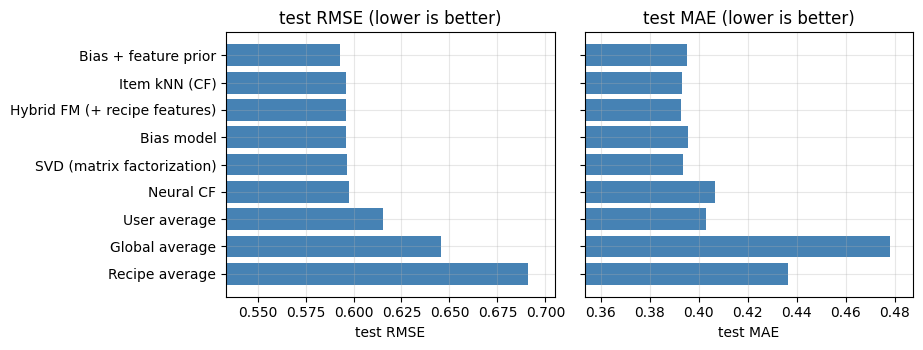

,val RMSE,val MAE,test RMSE,test MAE,test RMSE (warm recipes),test RMSE (cold recipes)
model,,,,,,
Global average,0.6530,0.4819,0.6456,0.4780,0.6312,0.7369
User average,0.6215,0.4066,0.6154,0.4028,0.6039,0.6894
Recipe average,0.6945,0.4388,0.6910,0.4363,0.6840,0.7369
Bias model,0.6027,0.3992,0.5963,0.3957,0.5823,0.6847
Item kNN (CF),0.6023,0.3966,0.5959,0.3930,0.5818,0.6847
SVD (matrix factorization),0.6030,0.3974,0.5968,0.3937,0.5825,0.6871
Neural CF,0.6040,0.4103,0.5978,0.4066,0.5850,0.6792
Hybrid FM (+ recipe features),0.6018,0.3963,0.5961,0.3928,0.5831,0.6789
Bias + feature prior,0.5990,0.3988,0.5929,0.3951,0.5801,0.6743


In [7]:
te = SPLIT["test"]; cold = te["i"] < 0
test_pred = {name: np.clip(f(te), 1, 5) for name, f in models.items()}
results = pd.DataFrame([{**val_score(name),
                         "test RMSE": rmse(te["r"], p), "test MAE": mae(te["r"], p),
                         "test RMSE (warm recipes)": rmse(te["r"][~cold], p[~cold]),
                         "test RMSE (cold recipes)": rmse(te["r"][cold], p[cold])}
                        for name, p in test_pred.items()]).set_index("model")
BEST = results["val RMSE"].idxmin()      # chosen on validation, not test
print(f"Best model (by validation RMSE): {BEST} | cold-start recipes are {cold.mean():.1%} of test")

fig, ax = plt.subplots(1, 2, figsize=(14 / 3 * 2, 3.6))
order = results.sort_values("test RMSE", ascending=False).index
for a, col in zip(ax, ["test RMSE", "test MAE"]):
    a.barh(order, results.loc[order, col], color="steelblue")
    lo = results[col].min()
    a.set_xlim(lo * 0.9, results[col].max() * 1.02)
    a.set_title(col + " (lower is better)"); a.set_xlabel(col)
ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()
results.round(4)

**Example predictions** (random test reviews, best model vs. the bias model):

In [8]:
rng = np.random.default_rng(SEED)
ex = rng.choice(len(test), 10, replace=False)
names = recipes.set_index("id").name
pd.DataFrame({"user": test.user_id.to_numpy()[ex],
              "recipe": names.loc[test.recipe_id.to_numpy()[ex]].str.strip().to_numpy(),
              "actual rating": te["r"][ex].astype(int),
              f"predicted ({BEST})": test_pred[BEST][ex].round(2),
              "predicted (bias model)": test_pred["Bias model"][ex].round(2)})

,user,recipe,actual rating,predicted (Bias + feature prior),predicted (bias model)
0,762568,sausage egg and cheese casserole,5,4.58,4.71
1,355885,fruited nut bars biscotti,5,4.82,4.84
2,171345,creamless celery potato soup,5,4.46,4.53
3,474322,awesome baked pork chops,5,4.85,4.87
4,929310,pineapple upside down minis,5,4.31,4.21
5,914720,tortilla dip supreme,5,4.81,4.80
6,174991,ham asparagus rolls,5,4.76,4.73
7,174096,5 layer mexican dip,5,4.95,4.98
8,310178,asian steamed salmon,5,4.91,4.81
9,89831,toffee bar coffee cake,5,5.00,5.00


**Where are the errors?** Error of the best model on the test set, broken down by:
- the **actual rating** (are low ratings harder?),
- how many **training reviews the user** has,
- how many **training reviews the recipe** has (0 = cold-start recipe).

The tables underneath compare with the global-average baseline.

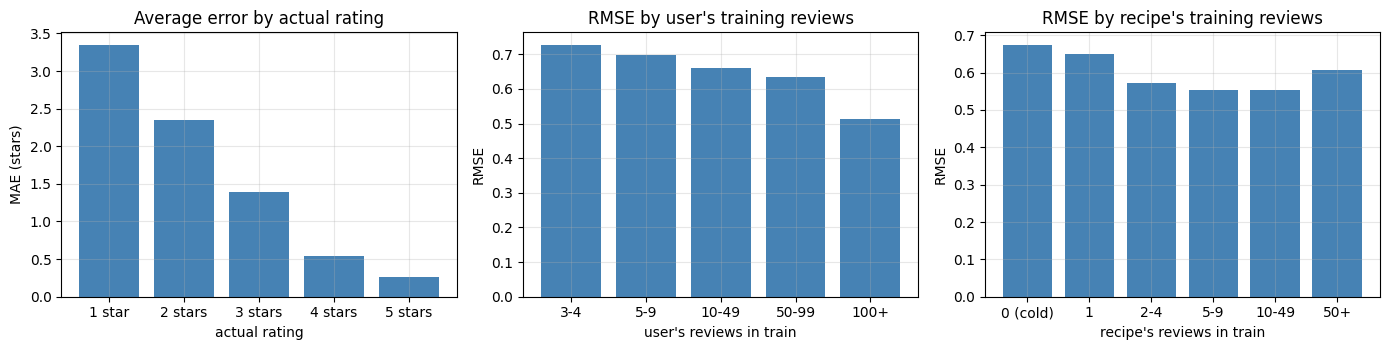

mean prediction by actual rating (Bias + feature prior): 1★: 4.35 | 2★: 4.35 | 3★: 4.40 | 4★: 4.53 | 5★: 4.74


,test reviews,% of test,RMSE (Bias + feature prior),RMSE (global avg),MAE (Bias + feature prior)
group,,,,,
1 star,430,0.545,3.370,3.683,3.347
2 stars,821,1.040,2.374,2.683,2.345
3 stars,2938,3.722,1.432,1.683,1.397
4 stars,14538,18.420,0.595,0.683,0.546
5 stars,60200,76.273,0.343,0.317,0.262


,test reviews,% of test,RMSE (Bias + feature prior),RMSE (global avg),MAE (Bias + feature prior)
group,,,,,
3-4,5008,6.345,0.727,0.760,0.471
5-9,5994,7.594,0.699,0.751,0.451
10-49,17816,22.573,0.660,0.710,0.431
50-99,8505,10.776,0.634,0.695,0.427
100+,41604,52.712,0.514,0.570,0.356


,test reviews,% of test,RMSE (Bias + feature prior),RMSE (global avg),MAE (Bias + feature prior)
group,,,,,
0 (cold),10021,12.697,0.674,0.737,0.464
1,8475,10.738,0.651,0.711,0.445
2-4,15963,20.225,0.572,0.628,0.396
5-9,12666,16.048,0.553,0.600,0.374
10-49,19748,25.021,0.553,0.603,0.362
50+,12054,15.272,0.608,0.653,0.377


In [9]:
p_best, p_glob, y = test_pred[BEST], test_pred["Global average"], te["r"]
user_n = lookup(n_u.astype(float), te["u"]); recipe_n = lookup(n_i.astype(float), te["i"])

def by_group(groups, labels):
    rows = []
    for g, lab in enumerate(labels):
        m = groups == g
        rows.append({"group": lab, "test reviews": int(m.sum()), "% of test": m.mean() * 100,
                     f"RMSE ({BEST})": rmse(y[m], p_best[m]), "RMSE (global avg)": rmse(y[m], p_glob[m]),
                     f"MAE ({BEST})": mae(y[m], p_best[m])})
    return pd.DataFrame(rows).set_index("group").round(3)

by_rating = by_group(y.astype(int) - 1, ["1 star", "2 stars", "3 stars", "4 stars", "5 stars"])
u_labels = ["3-4", "5-9", "10-49", "50-99", "100+"]
by_user = by_group(np.digitize(user_n, [5, 10, 50, 100]), u_labels)
r_labels = ["0 (cold)", "1", "2-4", "5-9", "10-49", "50+"]
by_recipe = by_group(np.digitize(recipe_n, [1, 2, 5, 10, 50]), r_labels)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar(by_rating.index, by_rating[f"MAE ({BEST})"], color="steelblue")
ax[0].set_title("Average error by actual rating"); ax[0].set_xlabel("actual rating"); ax[0].set_ylabel("MAE (stars)")
ax[1].bar(by_user.index, by_user[f"RMSE ({BEST})"], color="steelblue")
ax[1].set_title("RMSE by user's training reviews"); ax[1].set_xlabel("user's reviews in train"); ax[1].set_ylabel("RMSE")
ax[2].bar(by_recipe.index, by_recipe[f"RMSE ({BEST})"], color="steelblue")
ax[2].set_title("RMSE by recipe's training reviews"); ax[2].set_xlabel("recipe's reviews in train"); ax[2].set_ylabel("RMSE")
plt.tight_layout(); plt.show()

print(f"mean prediction by actual rating ({BEST}): " +
      " | ".join(f"{s}★: {p_best[y == s].mean():.2f}" for s in range(1, 6)))
display(by_rating); display(by_user); by_recipe

**Hardest users and recipes:** test users (with at least 10 test reviews) and recipes (at least 5 test reviews) with the highest RMSE under the best model, next to their training history.

In [10]:
d = pd.DataFrame({"user_id": test.user_id, "recipe_id": test.recipe_id, "y": y, "err2": (y - p_best) ** 2})
tr_user = train.groupby("user_id").rating.agg(train_reviews="size", train_mean="mean", train_std="std")
tr_recipe = train.groupby("recipe_id").rating.agg(train_reviews="size", train_mean="mean", train_std="std")

hard_users = (d.groupby("user_id").agg(test_reviews=("y", "size"), test_mean=("y", "mean"), RMSE=("err2", "mean"))
               .query("test_reviews >= 10").assign(RMSE=lambda t: np.sqrt(t.RMSE))
               .sort_values("RMSE", ascending=False).head(10).join(tr_user))
hard_recipes = (d.groupby("recipe_id").agg(test_reviews=("y", "size"), test_mean=("y", "mean"), RMSE=("err2", "mean"))
                 .query("test_reviews >= 5").assign(RMSE=lambda t: np.sqrt(t.RMSE))
                 .sort_values("RMSE", ascending=False).head(10).join(tr_recipe))
hard_recipes.insert(0, "name", names.loc[hard_recipes.index].str.strip())

all_users = d.groupby("user_id").agg(n=("y", "size"), RMSE=("err2", "mean")).query("n >= 10")
print(f"users with >= 10 test reviews: {len(all_users):,} | median RMSE {np.sqrt(all_users.RMSE).median():.3f}")
display(hard_users.round(2))
hard_recipes.round(2)

users with >= 10 test reviews: 1,350 | median RMSE 0.475


,test_reviews,test_mean,RMSE,train_reviews,train_mean,train_std
user_id,,,,,,
847160,10,3.30,1.68,96,4.20,0.98
833434,10,3.50,1.67,67,4.12,1.08
22655,11,3.73,1.64,106,4.08,1.05
170271,10,3.30,1.56,39,3.74,1.04
44642,17,3.82,1.50,96,4.33,1.33
1742738,11,4.09,1.49,58,4.72,0.72
63098,10,3.50,1.39,73,4.12,0.96
311926,24,3.79,1.34,110,4.15,0.99
203717,10,4.00,1.32,76,4.54,0.89


,name,test_reviews,test_mean,RMSE,train_reviews,train_mean,train_std
recipe_id,,,,,,,
18039,tender roast loin of pork,6,3.50,1.95,40,4.70,0.82
102058,basic whole wheat french crepes,6,3.67,1.85,16,4.88,0.34
53133,pork tenderloin with balsamic cranberry sauce,5,4.00,1.83,63,4.79,0.51
50684,world s best butter cookies,5,4.20,1.79,77,4.87,0.55
155616,sandi s black pepper cube steaks mushroom cr...,5,4.00,1.69,48,4.77,0.47
38584,yummy and super easy crock pot oatmeal,7,3.57,1.65,34,3.59,1.37
69191,pan fried tofu with spicy peanut sauce,12,3.83,1.65,64,4.55,0.83
87354,moroccan meatballs tagine kefta,5,3.80,1.65,26,4.50,0.86
155442,weight watchers mexican chicken breasts,6,4.17,1.65,60,4.87,0.50


## 6. A different setting: predicting the rating from the review text
Sections 1-5 predict a rating **before** the review is written, from who is rating which recipe. Here we change the question: **given the written review, what star rating goes with it?** (sentiment regression). This uses the review being scored, so these models are **not comparable** with Sections 1-5 and are kept out of that table. (Tom's notebook, Setting B, uses the same input to classify reviews as negative, ≤3★; here the target is the 1-5 score itself.)

- **Text features:** TF-IDF on 1-, 2- and 3-word phrases (bigrams catch "not good", "too salty"; trigrams catch "not very good", "will make again"). Lower-cased, `<br/>` and apostrophes removed; numbers, "!" and "?" kept as tokens ("5 stars", "Delicious!!"); no stop-word removal or stemming ("not", "but", "too" matter here). The 600,000 most frequent n-grams that appear in ≥3 training reviews; sublinear term frequency, rows L2-normalised. Built in two streaming passes (count, then fill the matrix) so the tokenised reviews never all sit in memory.
- **Tuning (validation RMSE, text only):** the original setting (words only, 1-2-grams, 100k) gave 0.4457; adding numbers/!/? 0.4426; 300k vocabulary 0.4422; adding 3-grams 0.4352; 600k vocabulary 0.4347.
- **Text only:** ridge regression from TF-IDF to the rating.
- **Text + bias/prior model:** ridge regression from TF-IDF to the *residual* of the Section 4b model, so the text explains what user/recipe history cannot.
- Ridge penalty $\alpha$ tuned on validation; test scored once. Solved by conjugate gradient on sparse PyTorch matrices.

In [ ]:
import re, math
from collections import Counter
t0 = time.time()
import warnings; warnings.filterwarnings("ignore", message="Sparse")    # torch's "sparse CSR is beta" notices
TOKEN_RE = re.compile(r"[a-z0-9]+|!|\?")
def text_tokens(s):
    w = TOKEN_RE.findall(re.sub(r"<br\s*/?>", " ", s.lower()).replace("'", ""))
    return w + [a + " " + b for a, b in zip(w, w[1:])] + [a + " " + b + " " + c for a, b, c in zip(w, w[1:], w[2:])]
reviews = {name: SPLIT[name]["df"].review.fillna("").astype(str).tolist() for name in SPLIT}

doc_freq = Counter()                                     # pass 1: document frequency of every n-gram in train
for s in reviews["train"]: doc_freq.update(set(text_tokens(s)))
keep = [x for x in doc_freq.most_common(600_000) if x[1] >= 3]
tvocab = {t: j for j, (t, _) in enumerate(keep)}
idf = np.array([math.log((1 + len(train)) / (1 + c)) + 1 for _, c in keep], np.float32)
del doc_freq, keep

def tfidf(texts):                                        # pass 2: one review at a time -> sparse CSR matrix
    crow, ccol, cval = np.zeros(len(texts) + 1, np.int64), [], []
    for k, s in enumerate(texts):
        c = Counter(j for j in map(tvocab.get, text_tokens(s)) if j is not None)
        idx = np.fromiter(c.keys(), np.int32, len(c)); v = (1 + np.log(np.fromiter(c.values(), np.float32, len(c)))) * idf[idx]
        o = np.argsort(idx); ccol.append(idx[o]); cval.append(v[o] / (np.sqrt((v ** 2).sum()) or 1.0)); crow[k + 1] = crow[k] + len(c)
    return torch.sparse_csr_tensor(torch.tensor(crow), torch.tensor(np.concatenate(ccol).astype(np.int64)),
                                   torch.tensor(np.concatenate(cval)), size=(len(texts), len(tvocab)))
TXT = {name: tfidf(t) for name, t in reviews.items()}
TXT_T = TXT["train"].t().to_sparse_csr()
print(f"TF-IDF: {len(tvocab):,} n-grams | {TXT['train'].values().numel():,} non-zeros in train | built in {time.time() - t0:.0f}s")

def ridge_text(y, alpha, w0=None, iters=600, tol=1e-7):
    """min ||X w + b - y||^2 + alpha ||w||^2 on the train TF-IDF matrix (conjugate gradient, warm-startable)."""
    y = torch.tensor(y, dtype=torch.float32); b = y.mean()
    A = lambda w: TXT_T @ (TXT["train"] @ w) + alpha * w
    w = torch.zeros(len(tvocab)) if w0 is None else w0.clone()
    r = TXT_T @ (y - b) - A(w); d = r.clone(); rs = r @ r; r0 = rs
    for _ in range(iters):
        Ad = A(d); a = rs / (d @ Ad); w += a * d; r -= a * Ad; rs_new = r @ r
        if rs_new < tol * r0: break
        d = r + rs_new / rs * d; rs = rs_new
    return w, b

base = {name: predict_prior(PRIOR, SPLIT[name]) for name in SPLIT}       # Section 4b model (no text)
targets = {"Text only (TF-IDF ridge)": (SPLIT["train"]["r"], {n: 0.0 for n in SPLIT}),
           "Text + bias/prior model": (SPLIT["train"]["r"] - base["train"], base)}
text_rows, text_pred = [], {}
for name, (y_target, offset) in targets.items():
    w, best = None, None
    for alpha in (10, 5, 3, 2, 1.5):                                      # large -> small, warm-started
        w, b = ridge_text(y_target, alpha, w)
        p = np.clip((TXT["valid"] @ w + b).numpy() + offset["valid"], 1, 5)
        text_rows.append({"model": name, "alpha": alpha, "val RMSE": rmse(SPLIT["valid"]["r"], p)})
        if best is None or text_rows[-1]["val RMSE"] < best[0]: best = (text_rows[-1]["val RMSE"], alpha, w.clone(), b)
    _, alpha, w, b = best
    text_pred[name] = {s: np.clip((TXT[s] @ w + b).numpy() + offset[s], 1, 5) for s in ("valid", "test")}
    if name.startswith("Text only"): TEXT_W = w
display(pd.DataFrame(text_rows).pivot(index="alpha", columns="model", values="val RMSE").round(4).style.set_caption("validation RMSE"))

y_te, stars = SPLIT["test"]["r"], SPLIT["test"]["r"].astype(int)
compare = {"Global average (no text)": test_pred["Global average"], f"{BEST} (no text)": test_pred[BEST],
           **{k: v["test"] for k, v in text_pred.items()}}
val_rmse = {"Global average (no text)": results.loc["Global average", "val RMSE"], f"{BEST} (no text)": results.loc[BEST, "val RMSE"],
            **{k: rmse(SPLIT["valid"]["r"], v["valid"]) for k, v in text_pred.items()}}
text_results = pd.DataFrame([{"model": k, "val RMSE": val_rmse[k],
                              "test RMSE": rmse(y_te, p), "test MAE": mae(y_te, p),
                              **{f"mean pred | {s}★": p[stars == s].mean() for s in range(1, 6)}} for k, p in compare.items()]).set_index("model")

fig, ax = plt.subplots(1, 2, figsize=(14 / 3 * 2, 3.6))
xs = np.arange(1, 6); width = 0.8 / len(compare)
for j, (k, p) in enumerate(compare.items()):
    ax[0].bar(xs + (j - (len(compare) - 1) / 2) * width, [p[stars == s].mean() for s in xs], width, label=k)
    ax[1].bar(xs + (j - (len(compare) - 1) / 2) * width, [rmse(y_te[stars == s], p[stars == s]) for s in xs], width, label=k)
ax[0].plot(xs, xs, "k--", lw=1, label="perfect"); ax[0].set_title("Mean prediction by actual rating (test)"); ax[0].set_xlabel("actual rating"); ax[0].set_ylabel("mean prediction")
ax[1].set_title("RMSE by actual rating (test)"); ax[1].set_xlabel("actual rating"); ax[1].set_ylabel("RMSE")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

names_t = np.array(sorted(tvocab, key=tvocab.get)); o = np.argsort(TEXT_W.numpy())
display(pd.DataFrame({"n-grams pulling the rating DOWN": names_t[o[:15]], "weight": TEXT_W.numpy()[o[:15]].round(2),
                      "n-grams pulling the rating UP": names_t[o[::-1][:15]], "weight ": TEXT_W.numpy()[o[::-1][:15]].round(2)}))
text_results.round(4)

## Findings
1. **Personalisation helps, but the bias model does almost all the work.** Every personalised model gets test RMSE ≈ 0.596, vs 0.646 for the global average (about 8% lower). Item kNN, SVD and the hybrid FM improve on the plain bias model by less than 0.001 RMSE; NCF is slightly worse. The one model that clearly helps keeps the bias structure and improves the *recipe bias* itself: the bias model with a feature-predicted recipe prior (Section 4b) reaches test RMSE 0.5929 vs 0.5963 (about 4x the gain of any other model), and it is the best model by validation RMSE. Most of what is predictable is "this user rates high/low" and "this recipe is rated high/low"; there is little extra user-recipe taste signal for latent factors to pick up.
2. **Regularisation matters more than model complexity.** The plain recipe average is *worse* than the global average (0.691 vs 0.646) because many recipes have only 1-2 ratings, so their averages are noisy. The regularised bias model fixes this. SVD and NCF overfit within a few epochs unless strongly regularised, and with strong regularisation they converge to the bias model.
3. **Recipe features help cold-start recipes, most of all as a prior on the recipe bias.** For test reviews on recipes never seen in train (12.7% of test), the hybrid FM lowers RMSE from 0.685 (bias model) to 0.679, and the feature-prior model to 0.674. The prior adds the recipe's author and the words in its name and description, and it uses the features only to set a recipe's *starting* bias, which its own ratings then override. Unlike the FM it also helps warm recipes (0.5823 → 0.5801), since recipes with 1-2 ratings are now pulled towards a sensible guess instead of towards 0. Its gains are in RMSE more than MAE (0.3951 vs 0.3957): it mostly trims the larger misses. Learned effects make sense: slow-cooker, "healthy" and casserole recipes rate lower; beverages, stews, roasts and grilled recipes rate higher.
4. **Low ratings are the hard part.** 76% of test reviews are 5 stars, so every model predicts around 4.4-4.8. A 1-star review is still predicted ≈ 4.4 (average miss ≈ 3.4 stars), while 5-star reviews are missed by ≈ 0.26. The 1-3 star reviews are only 5% of test but dominate the RMSE.
5. **More history = easier to predict.** RMSE drops from ≈ 0.73 for users with 3-4 training reviews to ≈ 0.52 for users with 100+, and is highest for cold-start (0.68) and one-review (0.65) recipes.
6. **Hardest users and recipes are inconsistent ones.** The hardest users have high-ish training averages (≈ 4.1-4.5) but a large spread (std ≈ 1), so their occasional low ratings can't be anticipated. The hardest recipes are popular, highly rated ones (training mean ≈ 4.7-4.9) that got a few unusually low reviews in test.

7. **The review text reveals the rating; user/recipe history mostly can't.** In the separate text setting (Section 6), TF-IDF ridge regression on the review itself reaches test RMSE 0.441 (vs 0.593 for the best history-only model, 26% lower), and adding the bias/prior model on top barely helps (0.440): once the words are known, who wrote them adds little. Most importantly it fixes the low-rating problem: 1★ reviews are predicted ≈ 2.97 on average instead of ≈ 4.35. Bigrams handle negation ("not disappointed", "not bland", "be sorry" push the rating *up*; "no flavor", "not good" push it down). This answers a different question from Sections 1-5 (it needs the written review), so it complements rather than replaces them.

**Possible next steps:** treat low ratings as their own problem (e.g. predict "will this user rate below 4?"), add time effects (users' rating drift), or use the time-based split to check the results hold when predicting the future.